In [3]:
from pathlib import Path
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

In [4]:
pth = Path('bird.png')
with Image.open(pth) as a:
    a = a.convert('RGB')
    img = np.array(a)
    img = img/255.0
    print(img.shape)

(768, 1408, 3)


In [5]:
flattened_img = img.reshape(-1,img.shape[2])
flattened_img.shape

(1081344, 3)

**Implementing K Means Clustering**

1. Find random K points from the samples (which are 3D vectors) to act as initial centroids
2. Calculate distance of all samples from K points and assign based on minimum distance 
3. Calculate centroids of resulting clusters 
4. Repeat from step 2 until centroid converges 

In [6]:
def compute_distance(centroid,data):
    # Need to subtract every data point from each centroid

    # distance = np.sqrt(((data[i,np.newaxis,:] - centroid)**2).sum(axis = 2)) prev logic
    distance = np.zeros((data.shape[0],centroid.shape[0]))
    for i in range(centroid.shape[0]):
        distance[:,i] = np.sqrt(((data - centroid[i])**2).sum(axis = 1)) # Much faster approach
    # print(distance)
    return distance # distance matrix of number of samples,centroids

In [7]:
def centroid_assign(centroid,data):
    assigments = np.argmin(compute_distance(centroid,data),axis=1) # picking index of min distance of each sample with centroid
    return assigments # index of closest centroids (1D) (no of samples)


In [8]:
def compute_centroid(centroid,data):
    assignments = centroid_assign(centroid,data)
    # print(assignments)
    K = {}
    centers = []
    for i in range(len(centroid)):
        s = np.argwhere(assignments == i).flatten()
        # print(s)
        if len(s) != 0 :
            K[tuple(np.mean(data[s],axis=0))] = data[s].tolist()
            centers.append(np.mean(data[s],axis=0))
        else:
            K[tuple(centroid[i])] = []
            centers.append(centroid[i]) 
    return K,centers
# centroids can have duplicate values but dic keys can't have duplicate, hence can overwrite , so we're storing the centroids separately


**Can be updated to include only a random sample of data points rather than all samples to calculate the centroids, much faster(batching)**

In [9]:
def clustering(iter,k,data,tol):
    centers = data[np.random.choice(data.shape[0],k,replace=False)]
    # print(centers)
    for i in range(iter):
        p,c = compute_centroid(centers,data)
        new_centers = np.array(c)  
        # print(new_centers)
        # print(f"Epoch {i+1}/{iter} Convergence : {np.sqrt(np.sum((new_centers - centers)**2))} Clusters : {p}")
        if np.sqrt(np.sum((new_centers - centers)**2)) < tol:
            return new_centers
        else:
            centers = new_centers
    return centers

# Original Image

(np.float64(-0.5), np.float64(1407.5), np.float64(767.5), np.float64(-0.5))

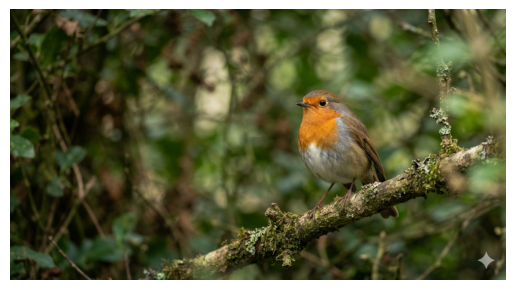

In [12]:
plt.imshow(img)
plt.axis('off')

# Transformed image using the centroids obtained from Clustering

In [16]:
import os
def image(k_value, original, flattened):
    # 1. Run the clustering algorithm 
    final_centroids = clustering(iter=10, k=k_value, data=flattened, tol=1e-4)
    
    # 2. Map every single one of the pixels to its nearest centroid index
    pixel_assignments = centroid_assign(final_centroids, flattened)
    
    # 3. Replace each original pixel color with its assigned centroid's color
    segmented_pixels = final_centroids[pixel_assignments]
    
    # 4. Reshape the segmented pixel array back to the original image dimensions
    reconstructed_img = segmented_pixels.reshape(original.shape[0], original.shape[1], original.shape[2])
    
    # 5. Save the image to the disk to evaluate compression footprint
    # Convert float back to standard 0-255 uint8 format for standard JPEG output
    compressed_filename = 'bird_transformed.png'
    final_img_uint8 = (reconstructed_img * 255.0).astype(np.uint8)
    Image.fromarray(final_img_uint8).save(compressed_filename)
    
    # 6. Fetch and print the file size statistics
    original_filename = 'bird.png' 
    try:
        orig_size_kb = os.path.getsize(original_filename) / 1024
        comp_size_kb = os.path.getsize(compressed_filename) / 1024
        savings = ((orig_size_kb - comp_size_kb) / orig_size_kb) * 100
        
        print("\n--- File Size Statistics ---")
        print(f" Original File Size ('{original_filename}'): {orig_size_kb:.2f} KB")
        print(f" Compressed File Size:              {comp_size_kb:.2f} KB")
        print(f" Storage Space Reduction:           {savings:.1f}% smaller!")
        print("----------------------------\n")
    except FileNotFoundError:
        print(f"\n Could not find '{original_filename}' on disk to verify original file size.")
        print(f" Compressed File Size: {os.path.getsize(compressed_filename) / 1024:.2f} KB\n")

    # 7. Display the image plots side by side
    plt.figure(figsize=(10, 5))
    
    plt.subplot(1, 2, 1)
    plt.imshow(original)
    plt.title("Original Image")
    plt.axis('off')
    
    plt.subplot(1, 2, 2)
    plt.imshow(reconstructed_img) 
    plt.title("Transformed Image")
    plt.axis('off')
    
    plt.show()


--- File Size Statistics ---
 Original File Size ('bird.png'): 1873.63 KB
 Compressed File Size:              51.71 KB
 Storage Space Reduction:           97.2% smaller!
----------------------------



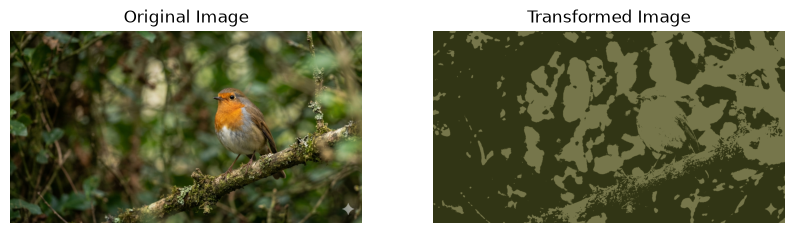

2

--- File Size Statistics ---
 Original File Size ('bird.png'): 1873.63 KB
 Compressed File Size:              144.64 KB
 Storage Space Reduction:           92.3% smaller!
----------------------------



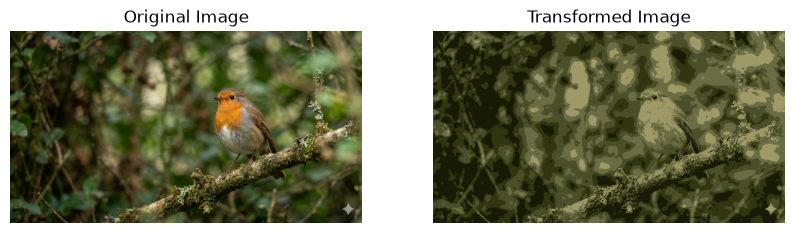

5

--- File Size Statistics ---
 Original File Size ('bird.png'): 1873.63 KB
 Compressed File Size:              264.25 KB
 Storage Space Reduction:           85.9% smaller!
----------------------------



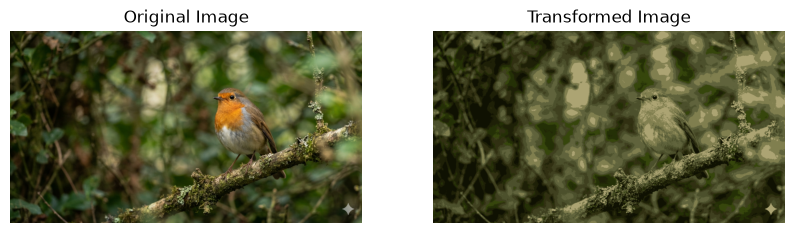

10

--- File Size Statistics ---
 Original File Size ('bird.png'): 1873.63 KB
 Compressed File Size:              410.80 KB
 Storage Space Reduction:           78.1% smaller!
----------------------------



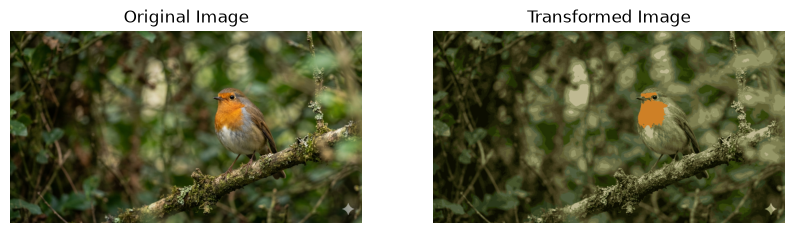

20

--- File Size Statistics ---
 Original File Size ('bird.png'): 1873.63 KB
 Compressed File Size:              539.71 KB
 Storage Space Reduction:           71.2% smaller!
----------------------------



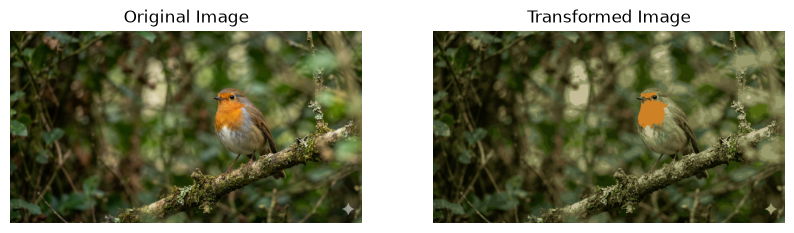

35

--- File Size Statistics ---
 Original File Size ('bird.png'): 1873.63 KB
 Compressed File Size:              696.07 KB
 Storage Space Reduction:           62.8% smaller!
----------------------------



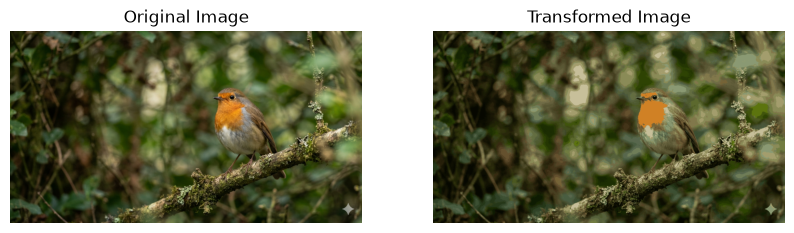

60
Exiting !!


In [17]:
while True:
    try:
        clusters = int(input("Enter the number of clusters you wish to have !!"))
        image(clusters, img, flattened_img)
        print(clusters)
        try_again = int(input("1- Try Again with different K or type anything to exit"))
        if try_again == 1:
            continue
        else:
            print("Exiting !!")
            break
    except Exception as e:
        print(f"An error occured {e} , Try Again !!")